# DỰ ÁN HỌC MÁY: XÂY DỰNG VÀ ĐÁNH GIÁ 5 MÔ HÌNH DỰ ĐOÁN Ý ĐỊNH MUA HÀNG
## (Online Shoppers Purchasing Intention Prediction)

---

### 1. Mục Tiêu Dự Án
Trong thương mại điện tử, việc hiểu và dự đoán hành vi khách hàng truy cập website là yếu tố then chốt giúp doanh nghiệp tối ưu hóa chiến dịch tiếp thị, cá nhân hóa ưu đãi và gia tăng tỷ lệ chuyển đổi đơn hàng.

Dự án này thực hiện một quy trình học máy (Machine Learning Pipeline) hoàn chỉnh từ con số 0 trên tập dữ liệu **Online Shoppers Purchasing Intention**:
* **Nhiệm vụ (Task):** Phân loại nhị phân (Binary Classification) - Dự đoán xem một phiên truy cập có đem lại doanh thu (`Revenue = True`) hay không (`Revenue = False`).
* **5 Mô hình máy học được xây dựng và so sánh:**
  1. **Logistic Regression** (Hồi quy Logistic - Mô hình tuyến tính xác suất)
  2. **K-Nearest Neighbors - KNN** (K láng giềng gần nhất - Mô hình học dựa trên khoảng cách)
  3. **Decision Tree** (Cây quyết định - Mô hình cấu trúc cây phân cấp)
  4. **Random Forest** (Rừng ngẫu nhiên - Mô hình Ensemble học kết hợp theo cơ chế Bagging)
  5. **Support Vector Machine - SVM** (Máy vector hỗ trợ - Mô hình tối đa hóa lề phân tách)

---

### 2. Quy Trình Chuẩn 5 Bước Cho Mỗi Mô Hình
Mỗi mô hình trong sổ tay này được thiết kế theo đúng quy trình chuẩn của một dự án Data Science chuyên nghiệp:
1. **Lý thuyết cốt lõi:** Cơ chế hoạt động, ưu & nhược điểm của thuật toán.
2. **Khởi tạo & Siêu tham số:** Giải thích chi tiết các tham số quan trọng (`Hyperparameters`).
3. **Huấn luyện mô hình:** Fit mô hình trên tập dữ liệu huấn luyện (`Train Set`).
4. **Dự đoán:** Dự đoán nhãn lớp (`y_pred`) và xác suất dự đoán (`y_prob`).
5. **Đánh giá toàn diện:** Ma trận nhầm lẫn (Confusion Matrix), Báo cáo phân loại (Precision, Recall, F1-Score), và Đường cong ROC (ROC-AUC).


In [1]:
# Import các thư viện xử lý dữ liệu và tính toán số học
import pandas as pd
import numpy as np
import time
import warnings
warnings.filterwarnings('ignore')

# Import các thư viện trực quan hóa dữ liệu
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập phong cách hiển thị biểu đồ
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

# Import các công cụ tiền xử lý và đánh giá từ Scikit-Learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report
)

# Import 5 mô hình học máy
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

print("✅ Đã import thành công toàn bộ thư viện cần thiết!")


✅ Đã import thành công toàn bộ thư viện cần thiết!


---
## BƯỚC 1: KHÁM PHÁ VÀ PHÂN TÍCH DỮ LIỆU (EDA)

Trong bước này, chúng ta sẽ:
* Đọc tập dữ liệu `online_shoppers_intention.csv`.
* Kiểm tra cấu trúc bảng (số dòng, số cột, kiểu dữ liệu `dtypes`).
* Thống kê mô tả các đặc trưng số và kiểm tra giá trị thiếu (`missing values`) hoặc trùng lặp (`duplicates`).
* Phân tích phân phối của nhãn mục tiêu `Revenue` để phát hiện hiện tượng mất cân bằng dữ liệu (Class Imbalance).
* Khảo sát mức độ tương quan giữa các đặc trưng quan trọng.


In [2]:
# Đọc tập dữ liệu CSV
df = pd.read_csv('online_shoppers_intention.csv')

print(f"Kích thước tập dữ liệu ban đầu: {df.shape[0]} dòng và {df.shape[1]} cột.")
print("-" * 60)
print("5 dòng đầu tiên của tập dữ liệu:")
df.head()


Kích thước tập dữ liệu ban đầu: 12330 dòng và 18 cột.
------------------------------------------------------------
5 dòng đầu tiên của tập dữ liệu:


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [3]:
# Kiểm tra thông tin kiểu dữ liệu và giá trị thiếu (Null/Missing)
print("=== THÔNG TIN KIỂU DỮ LIỆU VÀ GIÁ TRỊ NULL ===")
print(df.info())

print("\n" + "=" * 60)
# Kiểm tra số lượng dòng trùng lặp
n_duplicates = df.duplicated().sum()
print(f"Số lượng dòng bị trùng lặp: {n_duplicates}")

if n_duplicates > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"-> Đã loại bỏ trùng lặp. Kích thước tập dữ liệu hiện tại: {df.shape}")

print("\n" + "=" * 60)
print("Thống kê mô tả các đặc trưng số:")
df.describe().round(2)


=== THÔNG TIN KIỂU DỮ LIỆU VÀ GIÁ TRỊ NULL ===
<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null 

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12205.00,12205.00,12205.00,12205.00,12205.00,12205.00,12205.00,12205.00,12205.00,12205.00,12205.00,12205.00,12205.00,12205.00
mean,2.34,81.65,0.51,34.83,32.05,1206.98,0.02,0.04,5.95,0.06,2.12,2.36,3.15,4.07
std,3.33,177.49,1.28,141.42,44.59,1919.60,0.05,0.05,18.65,0.20,0.91,1.71,2.40,4.02
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,1.00,1.00,1.00
25%,0.00,0.00,0.00,0.00,8.00,193.00,0.00,0.01,0.00,0.00,2.00,2.00,1.00,2.00
50%,1.00,9.00,0.00,0.00,18.00,608.94,0.00,0.02,0.00,0.00,2.00,2.00,3.00,2.00
75%,4.00,94.70,0.00,0.00,38.00,1477.15,0.02,0.05,0.00,0.00,3.00,2.00,4.00,4.00
max,27.00,3398.75,24.00,2549.38,705.00,63973.52,0.20,0.20,361.76,1.00,8.00,13.00,9.00,20.00


### Phân tích biến mục tiêu `Revenue` (Doanh thu phiên truy cập)
Biến mục tiêu `Revenue` là một biến Boolean (`True`: Khách hàng mua hàng, `False`: Khách hàng không mua hàng).
Chúng ta sẽ kiểm tra xem dữ liệu có bị mất cân bằng nhãn (Class Imbalance) hay không.


Phân phối nhãn Revenue:
- False (Không mua): 10297 phiên (84.37%)
- True  (Có mua):    1908 phiên (15.63%)


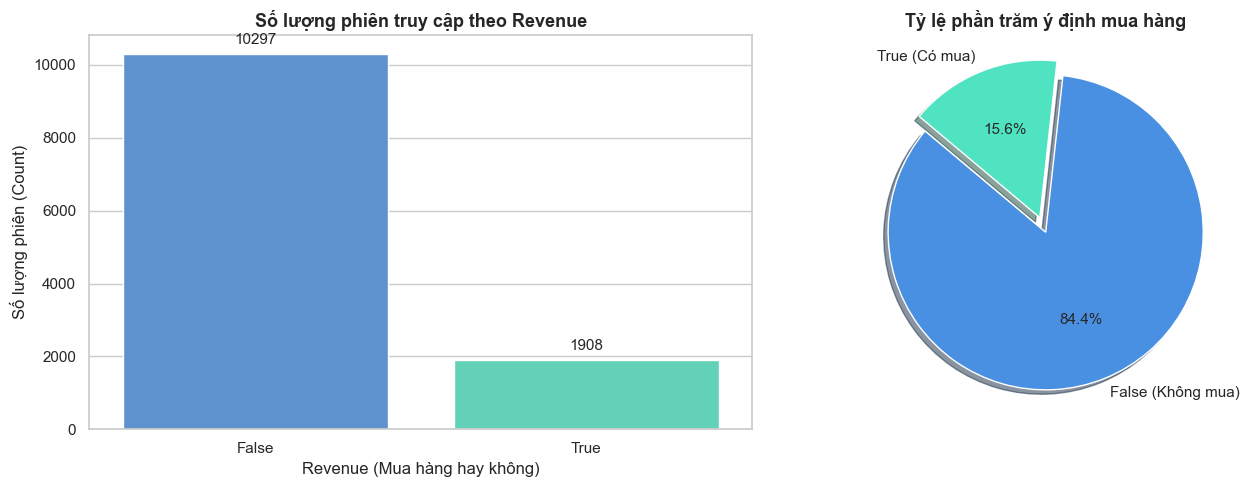

📌 NHẬN XÉT: Dữ liệu bị mất cân bằng rõ rệt (Khoảng 84.5% False vs 15.5% True).
Do đó, chỉ số Accuracy (độ chính xác tổng thể) sẽ không đủ tin cậy.
Chúng ta cần đặc biệt chú trọng các chỉ số: Precision, Recall, F1-Score và ROC-AUC!


In [4]:
# Đếm số lượng và tỷ lệ phần trăm của từng lớp trong Revenue
revenue_counts = df['Revenue'].value_counts()
revenue_pct = df['Revenue'].value_counts(normalize=True) * 100

print(f"Phân phối nhãn Revenue:")
print(f"- False (Không mua): {revenue_counts[False]} phiên ({revenue_pct[False]:.2f}%)")
print(f"- True  (Có mua):    {revenue_counts[True]} phiên ({revenue_pct[True]:.2f}%)")

# Trực quan hóa biến mục tiêu
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ đếm số lượng (Count plot)
sns.countplot(x='Revenue', data=df, ax=axes[0], palette=['#4A90E2', '#50E3C2'])
axes[0].set_title('Số lượng phiên truy cập theo Revenue', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Revenue (Mua hàng hay không)')
axes[0].set_ylabel('Số lượng phiên (Count)')
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height())}', 
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=11, xytext=(0, 5),
                     textcoords='offset points')

# Biểu đồ hình tròn tỷ lệ phần trăm (Pie chart)
axes[1].pie(revenue_counts, labels=['False (Không mua)', 'True (Có mua)'],
            autopct='%1.1f%%', colors=['#4A90E2', '#50E3C2'], 
            startangle=140, explode=[0, 0.1], shadow=True)
axes[1].set_title('Tỷ lệ phần trăm ý định mua hàng', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

print("📌 NHẬN XÉT: Dữ liệu bị mất cân bằng rõ rệt (Khoảng 84.5% False vs 15.5% True).")
print("Do đó, chỉ số Accuracy (độ chính xác tổng thể) sẽ không đủ tin cậy.")
print("Chúng ta cần đặc biệt chú trọng các chỉ số: Precision, Recall, F1-Score và ROC-AUC!")


### Phân tích tương quan & Các đặc trưng hành vi người dùng
Khảo sát mối tương quan giữa các biến số và xem xét sự phân bố của 2 đặc trưng quan trọng: `PageValues` (Giá trị trang) và `ExitRates` (Tỷ lệ thoát trang).


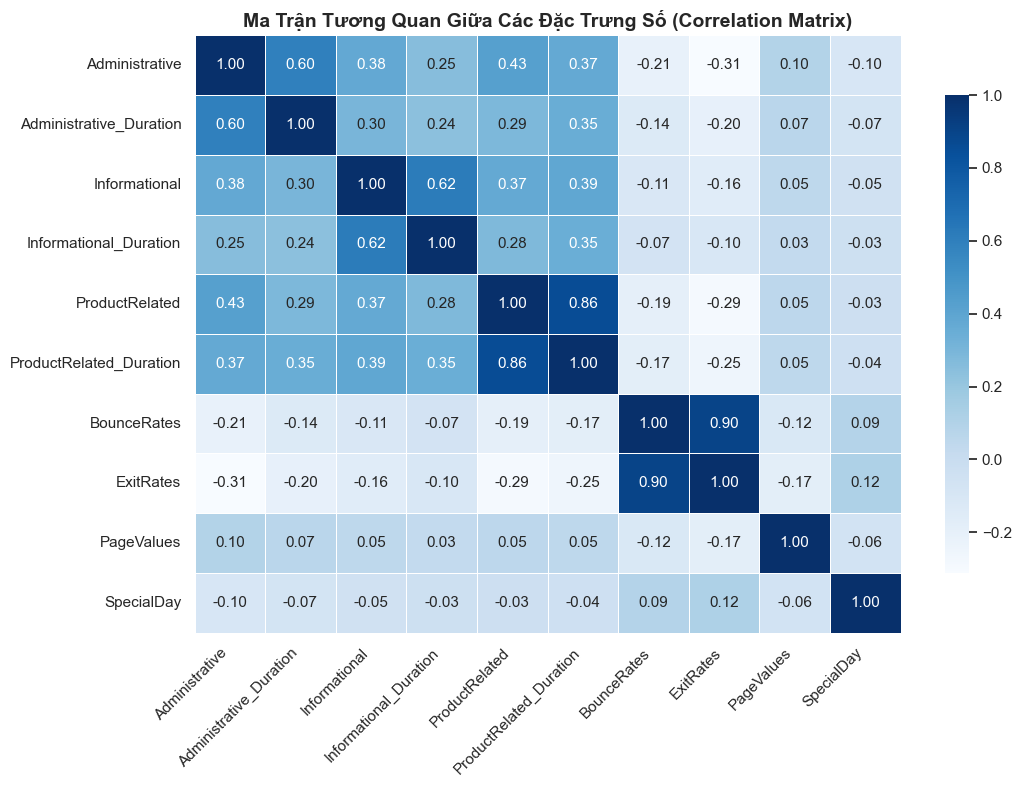

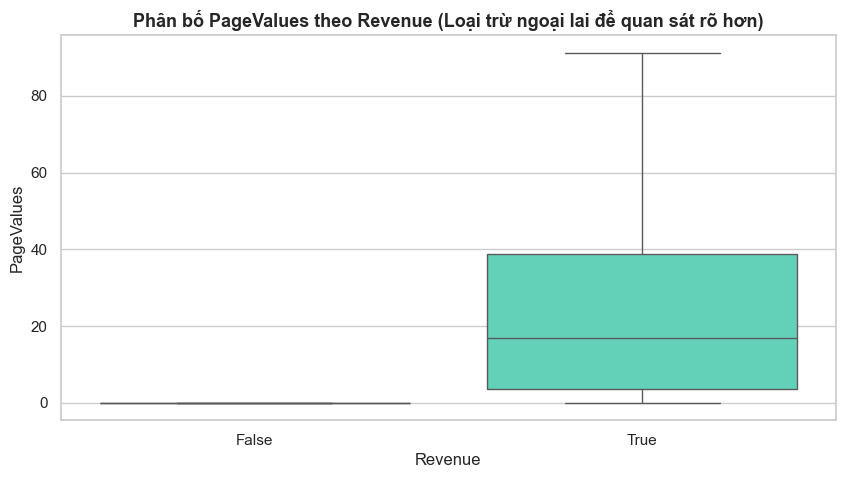

In [5]:
num_cols = [
    'Administrative', 'Administrative_Duration', 
    'Informational', 'Informational_Duration', 
    'ProductRelated', 'ProductRelated_Duration', 
    'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay'
]

plt.figure(figsize=(11, 8))
corr_matrix = df[num_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='Blues', linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('Ma Trận Tương Quan Giữa Các Đặc Trưng Số (Correlation Matrix)', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Trực quan hóa PageValues phân theo Revenue
plt.figure(figsize=(10, 5))
sns.boxplot(x='Revenue', y='PageValues', data=df, palette=['#4A90E2', '#50E3C2'], showfliers=False)
plt.title('Phân bố PageValues theo Revenue (Loại trừ ngoại lai để quan sát rõ hơn)', fontsize=13, fontweight='bold')
plt.xlabel('Revenue')
plt.ylabel('PageValues')
plt.show()


---
## BƯỚC 2: TIỀN XỬ LÝ DỮ LIỆU & KỸ THUẬT ĐẶC TRƯNG (PREPROCESSING)

Trong bước này, chúng ta thực hiện 4 công việc cốt lõi:
1. **Tách biến đặc trưng ($X$) và biến mục tiêu ($y$):**
   * $y$: Cột `Revenue` (được chuyển sang dạng số nguyên 0 và 1).
   * $X$: Các cột đặc trưng còn lại.
2. **Mã hóa biến phân loại (Categorical Encoding):**
   * Sử dụng kỹ thuật One-Hot Encoding (`pd.get_dummies` với `drop_first=True`) cho các thuộc tính phân loại: `Month`, `VisitorType`, `Weekend`, cũng như các mã định danh danh mục: `OperatingSystems`, `Browser`, `Region`, `TrafficType`.
   * Việc dùng `drop_first=True` giúp tránh bẫy đa cộng tuyến (Dummy Variable Trap).
3. **Phân chia tập dữ liệu Huấn luyện & Kiểm tra (Train/Test Split):**
   * Phân chia theo tỷ lệ **80% Train - 20% Test**.
   * Thiết lập `stratify=y` để bảo toàn nguyên vẹn tỷ lệ mất cân bằng giữa 2 lớp ở cả 2 tập.
   * Cố định `random_state=42` để đảm bảo tính tái lập (Reproducibility).
4. **Chuẩn hóa đặc trưng (Feature Scaling):**
   * Dùng `StandardScaler` để đưa các đặc trưng về phân phối chuẩn chuẩn tắc có trung bình $\mu = 0$ và độ lệch chuẩn $\sigma = 1$.
   * **Nguyên tắc sống còn:** Chỉ dùng `fit_transform` trên tập `X_train`, sau đó dùng `transform` trên `X_test` để ngăn ngừa rò rỉ dữ liệu (Data Leakage).


In [6]:
# 1. Tách X và y
X = df.drop(columns=['Revenue']).copy()
y = df['Revenue'].astype(int).copy()

# 2. Xác định danh sách các cột phân loại để One-Hot Encoding
categorical_features = ['Month', 'VisitorType', 'Weekend', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']

# Áp dụng One-Hot Encoding
X_encoded = pd.get_dummies(X, columns=categorical_features, drop_first=True, dtype=int)

print(f"Số lượng đặc trưng ban đầu: {X.shape[1]}")
print(f"Số lượng đặc trưng sau khi One-Hot Encoding: {X_encoded.shape[1]}")

# 3. Phân chia Train / Test (80% / 20%) có stratify
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Kích thước tập Train: {X_train.shape[0]} mẫu, {X_train.shape[1]} đặc trưng")
print(f"Kích thước tập Test:  {X_test.shape[0]} mẫu, {X_test.shape[1]} đặc trưng")
print(f"Tỷ lệ lớp 1 trong tập Train: {y_train.mean():.4f}")
print(f"Tỷ lệ lớp 1 trong tập Test:  {y_test.mean():.4f}")

# 4. Chuẩn hóa đặc trưng với StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Chuyển về DataFrame để dễ quan sát nếu cần
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X_encoded.columns)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=X_encoded.columns)

print("✅ Đã hoàn thành chuẩn hóa dữ liệu!")


Số lượng đặc trưng ban đầu: 17
Số lượng đặc trưng sau khi One-Hot Encoding: 68
Kích thước tập Train: 9764 mẫu, 68 đặc trưng
Kích thước tập Test:  2441 mẫu, 68 đặc trưng
Tỷ lệ lớp 1 trong tập Train: 0.1563
Tỷ lệ lớp 1 trong tập Test:  0.1565
✅ Đã hoàn thành chuẩn hóa dữ liệu!


In [7]:
# Tạo hàm tiện ích để đánh giá và trực quan hóa kết quả cho từng mô hình
model_results = {}

def evaluate_and_plot(model_name, y_true, y_pred, y_prob=None, train_time=0.0):
    """
    Hàm tính toán các chỉ số đánh giá, hiển thị ma trận nhầm lẫn và lưu kết quả vào từ điển.
    """
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    auc = roc_auc_score(y_true, y_prob) if y_prob is not None else np.nan
    
    # Lưu vào từ điển so sánh
    model_results[model_name] = {
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': auc,
        'Train Time (s)': round(train_time, 4),
        'y_pred': y_pred,
        'y_prob': y_prob
    }
    
    # In báo cáo phân loại chi tiết
    print(f"================ BÁO CÁO HIỆU NĂNG: {model_name.upper()} ================")
    print(f"Accuracy  (Độ chính xác tổng thể):  {acc * 100:.2f}%")
    print(f"Precision (Độ chuẩn xác lớp Mua):    {prec * 100:.2f}%")
    print(f"Recall    (Độ thu hồi lớp Mua):       {rec * 100:.2f}%")
    print(f"F1-Score  (Trung bình điều hòa):     {f1 * 100:.2f}%")
    if y_prob is not None:
        print(f"ROC-AUC   (Chỉ số diện tích ROC):    {auc:.4f}")
    print(f"Thời gian huấn luyện:                {train_time:.4f} giây")
    print("-" * 65)
    print("Báo cáo phân loại chi tiết (Classification Report):")
    print(classification_report(y_true, y_pred, target_names=['Không mua (0)', 'Có mua (1)']))
    
    # Trực quan hóa Ma trận nhầm lẫn (Confusion Matrix) và Đường cong ROC
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # 1. Confusion Matrix Heatmap
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
                xticklabels=['Dự đoán: Không', 'Dự đoán: Có'],
                yticklabels=['Thực tế: Không', 'Thực tế: Có'])
    axes[0].set_title(f'Ma Trận Nhầm Lẫn - {model_name}', fontsize=12, fontweight='bold')
    
    # 2. ROC Curve
    if y_prob is not None:
        fpr, tpr, _ = roc_curve(y_true, y_prob)
        axes[1].plot(fpr, tpr, color='#E74C3C', lw=2.5, label=f'ROC curve (AUC = {auc:.4f})')
        axes[1].plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label='Phân loại ngẫu nhiên')
        axes[1].set_xlim([0.0, 1.0])
        axes[1].set_ylim([0.0, 1.05])
        axes[1].set_xlabel('False Positive Rate (FPR)')
        axes[1].set_ylabel('True Positive Rate (TPR / Recall)')
        axes[1].set_title(f'Đường Cong ROC - {model_name}', fontsize=12, fontweight='bold')
        axes[1].legend(loc="lower right")
    else:
        axes[1].text(0.5, 0.5, 'Mô hình không hỗ trợ xác suất', ha='center', va='center')
        axes[1].set_title('Đường Cong ROC (N/A)')
        
    plt.tight_layout()
    plt.show()

print("✅ Đã khởi tạo hàm đánh giá mô hình tiện ích!")


✅ Đã khởi tạo hàm đánh giá mô hình tiện ích!


---
## BƯỚC 3: MÔ HÌNH 1 - HỒI QUY LOGISTIC (LOGISTIC REGRESSION)

### 1. Cơ sở lý thuyết
* Hồi quy Logistic là mô hình phân loại tuyến tính cổ điển dựa trên việc ánh xạ tổ hợp tuyến tính của các đặc trưng thông qua hàm kích hoạt **Sigmoid (Logistic Function)**:
  $$P(y=1|X) = \sigma(z) = \frac{1}{1 + e^{-z}}, \quad \text{với } z = w^T X + b$$
* **Log-Odds:** $\ln\left(\frac{P}{1-P}\right) = w^T X + b$. Trọng số $w$ thể hiện sự thay đổi của log-odds khi đặc trưng tăng 1 đơn vị.
* **Ưu điểm:**
  * Tính toán cực kỳ nhanh, độ phức tạp thấp.
  * Có khả năng giải thích tốt (Interpretable): biết được đặc trưng nào thúc đẩy hoặc cản trở quyết định mua hàng qua hệ số trọng số.
  * Phù hợp tuyệt vời làm mốc cơ sở (**Baseline Model**) để so sánh với các thuật toán phức tạp hơn.
* **Nhược điểm:**
  * Giả định quan hệ đơn điệu tuyến tính giữa log-odds và các đặc trưng; khó biểu diễn tốt tương tác phi tuyến tính phức tạp.
  * Nhạy cảm với các đặc trưng có thang đo chênh lệch lớn (do đó bắt buộc dùng dữ liệu đã chuẩn hóa `X_train_scaled`).

### 2. Thiết lập siêu tham số (Hyperparameters)
* `max_iter=1000`: Số vòng lặp tối đa để thuật toán tối ưu hóa hội tụ.
* `C=1.0`: Tham số điều hòa nghịch đảo (Inverse of regularization strength). $C$ càng nhỏ thì ràng buộc phạt càng mạnh để tránh overfitting.
* `solver='lbfgs'`: Thuật toán Quasi-Newton tối ưu hóa hàm mất mát Log-loss.
* `random_state=42`: Cố định ngẫu nhiên để kết quả hoàn toàn tái lập.


================ BÁO CÁO HIỆU NĂNG: LOGISTIC REGRESSION ================
Accuracy  (Độ chính xác tổng thể):  88.78%
Precision (Độ chuẩn xác lớp Mua):    75.47%
Recall    (Độ thu hồi lớp Mua):       41.88%
F1-Score  (Trung bình điều hòa):     53.87%
ROC-AUC   (Chỉ số diện tích ROC):    0.8981
Thời gian huấn luyện:                0.0160 giây
-----------------------------------------------------------------
Báo cáo phân loại chi tiết (Classification Report):
               precision    recall  f1-score   support

Không mua (0)       0.90      0.97      0.94      2059
   Có mua (1)       0.75      0.42      0.54       382

     accuracy                           0.89      2441
    macro avg       0.83      0.70      0.74      2441
 weighted avg       0.88      0.89      0.87      2441



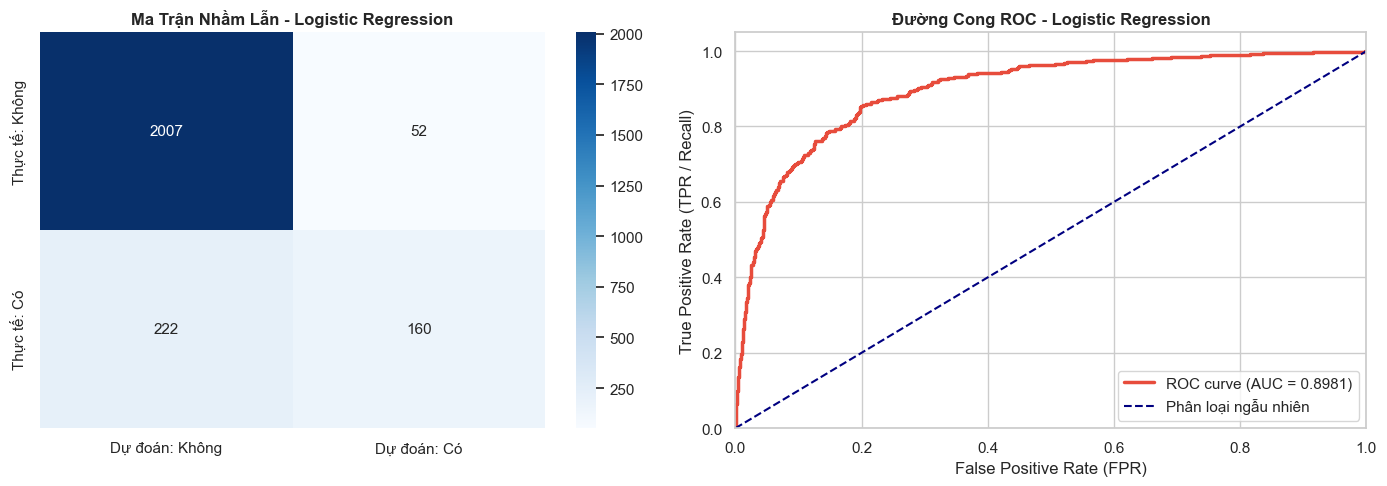

Top 5 đặc trưng thúc đẩy mua hàng mạnh nhất (Hệ số dương lớn nhất):
  + PageValues                    : +1.5259
  + Month_Nov                     : +0.1929
  + ProductRelated_Duration       : +0.1370
  + TrafficType_10                : +0.1128
  + OperatingSystems_2            : +0.1109

Top 5 đặc trưng cản trở mua hàng nhất (Hệ số âm lớn nhất):
  - ExitRates                     : -0.7728
  - Month_Dec                     : -0.2597
  - Month_May                     : -0.2232
  - Month_Mar                     : -0.2138
  - TrafficType_15                : -0.2126


In [8]:
# 1. Khởi tạo mô hình Logistic Regression
log_reg = LogisticRegression(
    max_iter=1000,
    C=1.0,
    solver='lbfgs',
    random_state=42
)

# 2. Huấn luyện mô hình trên dữ liệu đã chuẩn hóa (StandardScaled)
start_time = time.time()
log_reg.fit(X_train_scaled, y_train)
lr_train_time = time.time() - start_time

# 3. Dự đoán nhãn lớp và xác suất trên tập Test
y_pred_lr = log_reg.predict(X_test_scaled)
y_prob_lr = log_reg.predict_proba(X_test_scaled)[:, 1]

# 4. Đánh giá toàn diện
evaluate_and_plot('Logistic Regression', y_test, y_pred_lr, y_prob_lr, lr_train_time)

# 5. Phân tích trọng số đặc trưng quan trọng nhất (Feature Coefficients)
lr_coefs = pd.Series(log_reg.coef_[0], index=X_encoded.columns)
top_pos_coefs = lr_coefs.nlargest(5)
top_neg_coefs = lr_coefs.nsmallest(5)

print("Top 5 đặc trưng thúc đẩy mua hàng mạnh nhất (Hệ số dương lớn nhất):")
for feat, val in top_pos_coefs.items():
    print(f"  + {feat:30s}: {val:+.4f}")

print("\nTop 5 đặc trưng cản trở mua hàng nhất (Hệ số âm lớn nhất):")
for feat, val in top_neg_coefs.items():
    print(f"  - {feat:30s}: {val:+.4f}")


---
## BƯỚC 4: MÔ HÌNH 2 - K LÁNG GIỀNG GẦN NHẤT (K-NEAREST NEIGHBORS - KNN)

### 1. Cơ sở lý thuyết
* KNN là một thuật toán **phi tham số (Non-parametric)** và thuộc nhóm **học lười (Lazy Learning / Instance-based)**:
  * Trong giai đoạn huấn luyện, mô hình thực chất chỉ lưu trữ toàn bộ dữ liệu mẫu trong bộ nhớ.
  * Khi cần dự đoán một điểm dữ liệu mới $x$, thuật toán tính toán khoảng cách từ $x$ đến tất cả các điểm trong tập huấn luyện.
  * Chọn ra $K$ điểm có khoảng cách gần nhất và thực hiện bỏ phiếu đa số (Majority Voting) để quyết định nhãn lớp.
* **Khoảng cách thường dùng:** Khoảng cách Euclidean (chuẩn $L_2$):
  $$d(x, x') = \sqrt{\sum_{i=1}^{D} (x_i - x'_i)^2}$$
* **Ưu điểm:**
  * Trực quan, cực kỳ dễ hiểu về mặt trực giác.
  * Không đưa ra giả định gì về phân phối của dữ liệu, có thể học được các biên phân tách phi tuyến phức tạp.
* **Nhược điểm:**
  * Bắt buộc phải chuẩn hóa dữ liệu vì các đặc trưng có thang đo lớn sẽ lấn át hoàn toàn khoảng cách Euclidean.
  * Chi phí tính toán khi dự đoán rất cao ($O(N \times D)$), tốn bộ nhớ và nhạy cảm với hiện tượng "Lời nguyền số chiều" (Curse of Dimensionality).

### 2. Thiết lập siêu tham số (Hyperparameters)
* `n_neighbors=7`: Số lượng láng giềng $K$ được chọn (chọn số lẻ để tránh trường hợp hòa phiếu).
* `weights='uniform'`: Tất cả $K$ láng giềng đều có trọng số bỏ phiếu ngang nhau.
* `metric='minkowski'`, `p=2`: Sử dụng khoảng cách Euclidean tiêu chuẩn.


================ BÁO CÁO HIỆU NĂNG: K-NEAREST NEIGHBORS (KNN) ================
Accuracy  (Độ chính xác tổng thể):  85.54%
Precision (Độ chuẩn xác lớp Mua):    62.61%
Recall    (Độ thu hồi lớp Mua):       18.85%
F1-Score  (Trung bình điều hòa):     28.97%
ROC-AUC   (Chỉ số diện tích ROC):    0.7165
Thời gian huấn luyện:                0.0020 giây
-----------------------------------------------------------------
Báo cáo phân loại chi tiết (Classification Report):
               precision    recall  f1-score   support

Không mua (0)       0.87      0.98      0.92      2059
   Có mua (1)       0.63      0.19      0.29       382

     accuracy                           0.86      2441
    macro avg       0.75      0.58      0.60      2441
 weighted avg       0.83      0.86      0.82      2441



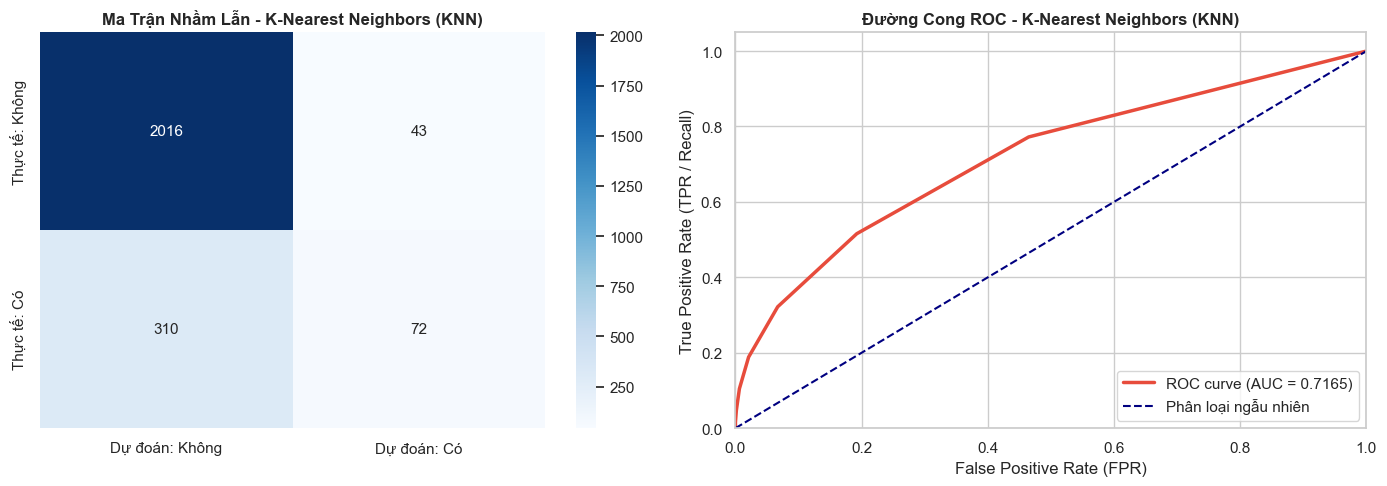

In [9]:
# 1. Khởi tạo mô hình KNN
knn = KNeighborsClassifier(
    n_neighbors=7,
    weights='uniform',
    metric='minkowski',
    p=2
)

# 2. Huấn luyện mô hình (Fit dữ liệu đã chuẩn hóa)
start_time = time.time()
knn.fit(X_train_scaled, y_train)
knn_train_time = time.time() - start_time

# 3. Dự đoán nhãn lớp và xác suất trên tập Test
y_pred_knn = knn.predict(X_test_scaled)
y_prob_knn = knn.predict_proba(X_test_scaled)[:, 1]

# 4. Đánh giá toàn diện
evaluate_and_plot('K-Nearest Neighbors (KNN)', y_test, y_pred_knn, y_prob_knn, knn_train_time)


---
## BƯỚC 5: MÔ HÌNH 3 - CÂY QUYẾT ĐỊNH (DECISION TREE)

### 1. Cơ sở lý thuyết
* Cây quyết định phân chia không gian đặc trưng một cách đệ quy thành các siêu hình hộp chữ nhật thông qua các câu hỏi điều kiện nhị phân (ví dụ: `PageValues <= 0.5`).
* Tiêu chí phân nhánh phổ biến là **Độ vẫn đục Gini (Gini Impurity)**:
  $$\text{Gini}(t) = 1 - \sum_{i=1}^{C} p_i^2$$
  Mỗi bước phân nhánh sẽ chọn đặc trưng và ngưỡng phân chia sao cho độ giảm Gini (Gini Gain) là lớn nhất.
* **Ưu điểm:**
  * Khả năng giải thích cực kỳ cao (White-box model) - con người có thể theo dõi từng nhánh quyết định.
  * Không đòi hỏi chuẩn hóa đặc trưng (bất biến với phép biến đổi đơn điệu).
  * Tự động phát hiện mối quan hệ phi tuyến và tương tác giữa các thuộc tính.
* **Nhược điểm:**
  * Rất dễ bị **quá khớp (Overfitting)** nếu cây phát triển quá sâu và ghi nhớ cả nhiễu của tập huấn luyện.
  * Cần kỹ thuật cắt tỉa cây (Pruning) hoặc kiểm soát độ sâu (`max_depth`).

### 2. Thiết lập siêu tham số (Hyperparameters)
* `criterion='gini'`: Tiêu chuẩn đánh giá chất lượng phân nhánh.
* `max_depth=5`: Giới hạn độ sâu tối đa của cây ở mức 5 tầng để kiểm soát overfitting và giữ cho mô hình trực quan.
* `min_samples_split=20`: Mỗi nút phải có tối thiểu 20 mẫu mới được tiếp tục chia nhánh.
* `min_samples_leaf=10`: Mỗi nút lá phải chứa ít nhất 10 mẫu để tránh tạo các nhánh quá cá biệt.
* `random_state=42`: Đảm bảo tính tái lập.


================ BÁO CÁO HIỆU NĂNG: DECISION TREE ================
Accuracy  (Độ chính xác tổng thể):  90.21%
Precision (Độ chuẩn xác lớp Mua):    70.85%
Recall    (Độ thu hồi lớp Mua):       63.61%
F1-Score  (Trung bình điều hòa):     67.03%
ROC-AUC   (Chỉ số diện tích ROC):    0.9256
Thời gian huấn luyện:                0.0275 giây
-----------------------------------------------------------------
Báo cáo phân loại chi tiết (Classification Report):
               precision    recall  f1-score   support

Không mua (0)       0.93      0.95      0.94      2059
   Có mua (1)       0.71      0.64      0.67       382

     accuracy                           0.90      2441
    macro avg       0.82      0.79      0.81      2441
 weighted avg       0.90      0.90      0.90      2441



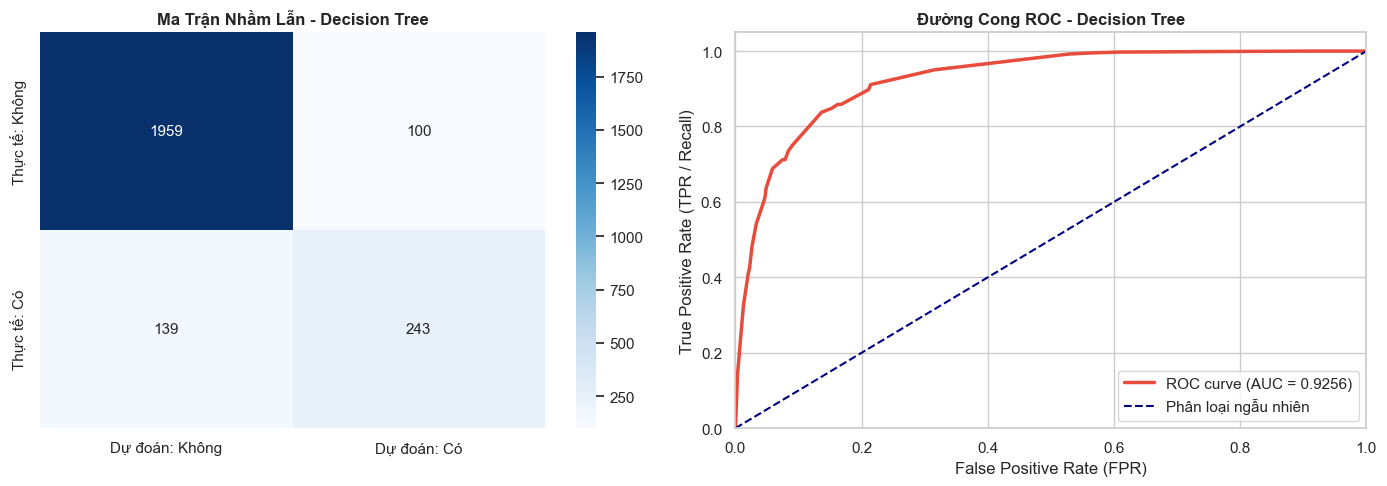

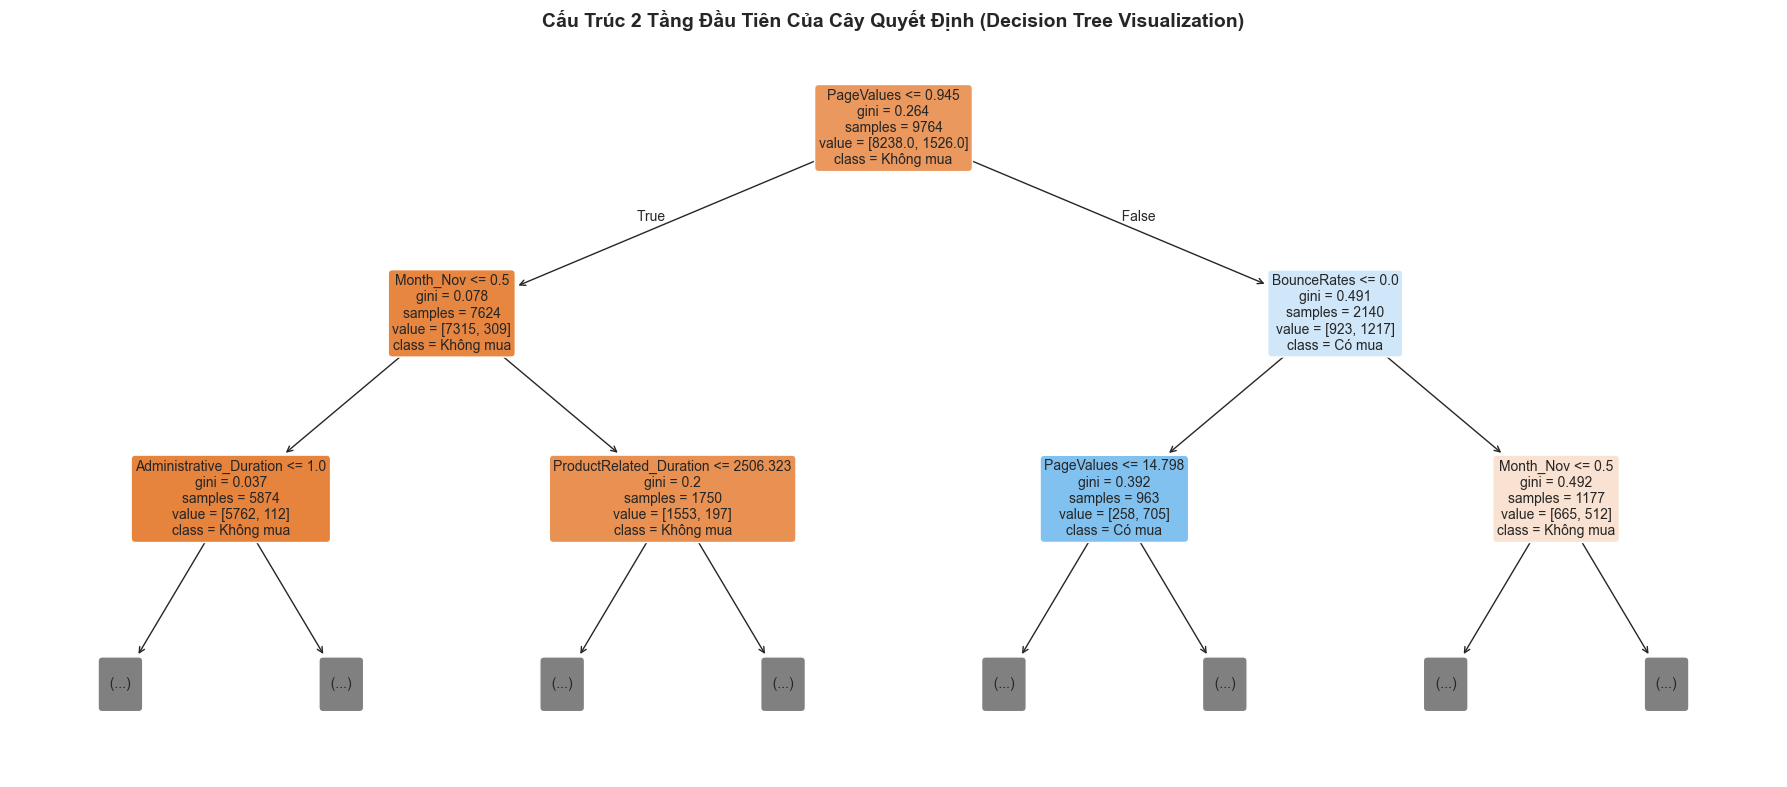

📌 Ghi chú: Nút gốc (Root Node) chọn đặc trưng 'PageValues' để phân nhánh đầu tiên.
Điều này khẳng định 'PageValues' chính là nhân tố quyết định then chốt nhất!


In [10]:
# 1. Khởi tạo mô hình Decision Tree với siêu tham số kiểm soát độ sâu
dt = DecisionTreeClassifier(
    criterion='gini',
    max_depth=5,
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42
)

# 2. Huấn luyện mô hình (Cây quyết định hoạt động xuất sắc trên dữ liệu gốc X_train mà không bắt buộc scale)
start_time = time.time()
dt.fit(X_train, y_train)
dt_train_time = time.time() - start_time

# 3. Dự đoán trên tập Test
y_pred_dt = dt.predict(X_test)
y_prob_dt = dt.predict_proba(X_test)[:, 1]

# 4. Đánh giá toàn diện
evaluate_and_plot('Decision Tree', y_test, y_pred_dt, y_prob_dt, dt_train_time)

# 5. Trực quan hóa cấu trúc nhánh cây quyết định (Hiển thị 2 tầng đầu tiên để quan sát trực quan)
plt.figure(figsize=(18, 8))
plot_tree(
    dt,
    max_depth=2,
    feature_names=X_encoded.columns.tolist(),
    class_names=['Không mua', 'Có mua'],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title('Cấu Trúc 2 Tầng Đầu Tiên Của Cây Quyết Định (Decision Tree Visualization)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("📌 Ghi chú: Nút gốc (Root Node) chọn đặc trưng 'PageValues' để phân nhánh đầu tiên.")
print("Điều này khẳng định 'PageValues' chính là nhân tố quyết định then chốt nhất!")


---
## BƯỚC 6: MÔ HÌNH 4 - RỪNG NGẪU NHIÊN (RANDOM FOREST)

### 1. Cơ sở lý thuyết
* Random Forest là phương pháp học kết hợp **Ensemble Learning** sử dụng kỹ thuật **Bagging (Bootstrap Aggregating)**:
  1. **Bootstrapping:** Rút ngẫu nhiên có hoàn lại nhiều tập con dữ liệu từ tập huấn luyện ban đầu.
  2. **Feature Randomness:** Tại mỗi nút phân nhánh của mỗi cây con, chỉ một tập con ngẫu nhiên các đặc trưng được xem xét (thường là $\sqrt{D}$).
  3. **Aggregating:** Khi dự đoán, mô hình lấy biểu quyết đa số (Majority Voting) hoặc tính trung bình xác suất của tất cả các cây con.
* **Ưu điểm:**
  * Giảm mạnh phương sai (Variance) mà không làm tăng độ chệch (Bias), khắc phục triệt để nhược điểm overfitting của cây quyết định đơn lẻ.
  * Hiệu năng dự đoán vượt trội, luôn thuộc top những thuật toán mạnh nhất cho dữ liệu dạng bảng (Tabular Data).
  * Cung cấp chỉ số đo lường độ quan trọng của đặc trưng (**Feature Importance**) đáng tin cậy.
* **Nhược điểm:**
  * Mất đi tính trực quan từng bước của một cây đơn lẻ (mô hình hộp xám - Grey-box).
  * Tốn nhiều thời gian huấn luyện và dung lượng lưu trữ hơn so với một cây đơn lẻ.

### 2. Thiết lập siêu tham số (Hyperparameters)
* `n_estimators=100`: Xây dựng tập hợp 100 cây quyết định độc lập.
* `max_depth=10`: Độ sâu tối đa của mỗi cây trong rừng.
* `min_samples_split=10`, `min_samples_leaf=5`: Kiểm soát độ phức tạp của từng cây.
* `random_state=42`: Cố định tính ngẫu nhiên.
* `n_jobs=-1`: Tận dụng toàn bộ các lõi CPU của máy để huấn luyện song song tốc độ cao.


================ BÁO CÁO HIỆU NĂNG: RANDOM FOREST ================
Accuracy  (Độ chính xác tổng thể):  89.92%
Precision (Độ chuẩn xác lớp Mua):    80.09%
Recall    (Độ thu hồi lớp Mua):       47.38%
F1-Score  (Trung bình điều hòa):     59.54%
ROC-AUC   (Chỉ số diện tích ROC):    0.9292
Thời gian huấn luyện:                0.1429 giây
-----------------------------------------------------------------
Báo cáo phân loại chi tiết (Classification Report):
               precision    recall  f1-score   support

Không mua (0)       0.91      0.98      0.94      2059
   Có mua (1)       0.80      0.47      0.60       382

     accuracy                           0.90      2441
    macro avg       0.86      0.73      0.77      2441
 weighted avg       0.89      0.90      0.89      2441



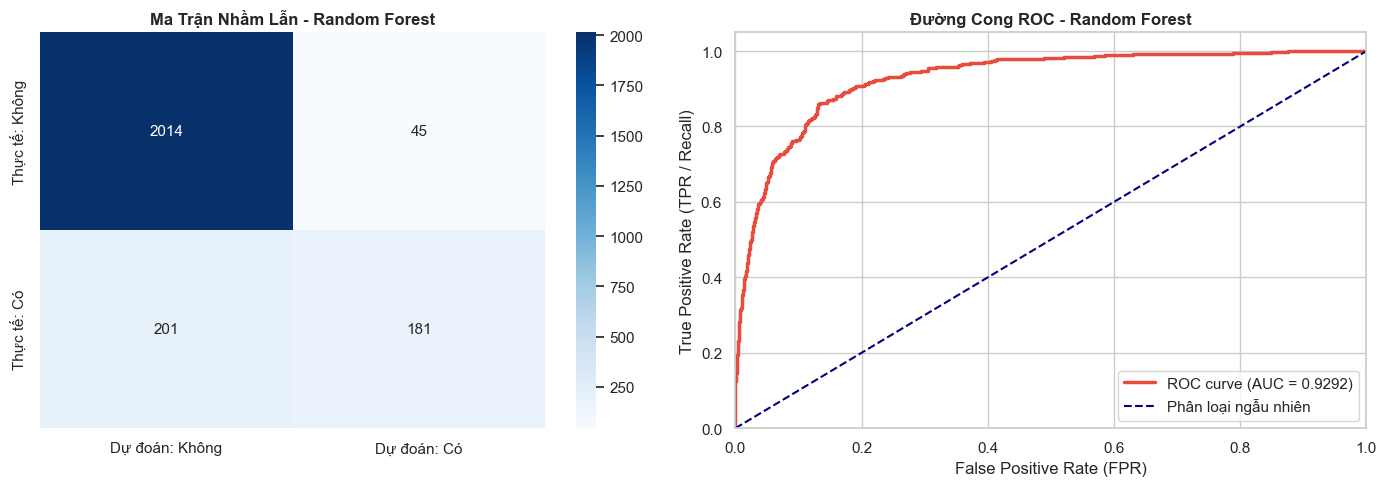

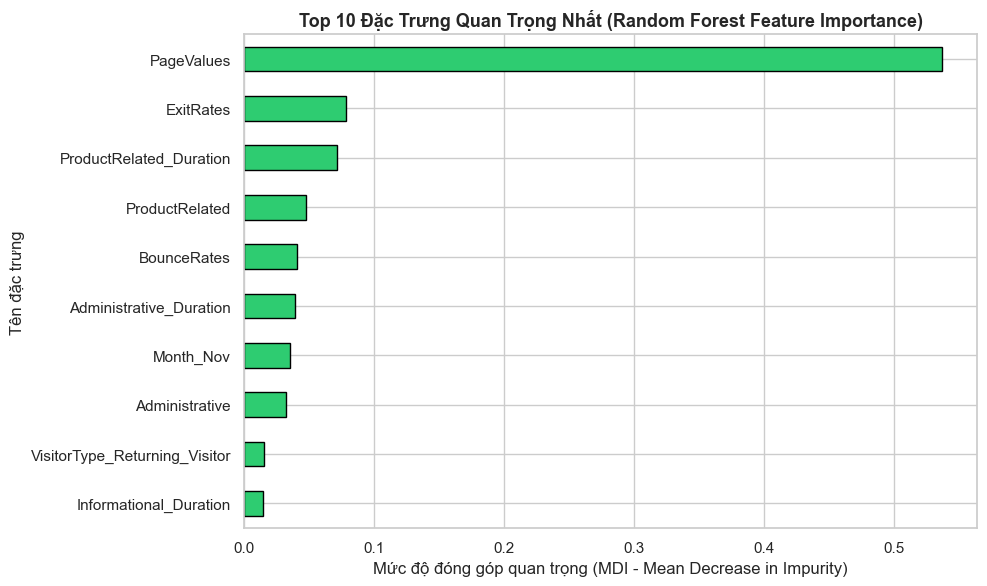

In [11]:
# 1. Khởi tạo Random Forest Classifier
rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

# 2. Huấn luyện mô hình Random Forest
start_time = time.time()
rf.fit(X_train, y_train)
rf_train_time = time.time() - start_time

# 3. Dự đoán trên tập Test
y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:, 1]

# 4. Đánh giá toàn diện
evaluate_and_plot('Random Forest', y_test, y_pred_rf, y_prob_rf, rf_train_time)

# 5. Phân tích và trực quan hóa Feature Importance (Top 10 đặc trưng quan trọng nhất)
feat_importances = pd.Series(rf.feature_importances_, index=X_encoded.columns)
top_10_features = feat_importances.nlargest(10).sort_values(ascending=True)

plt.figure(figsize=(10, 6))
top_10_features.plot(kind='barh', color='#2ECC71', edgecolor='black')
plt.title('Top 10 Đặc Trưng Quan Trọng Nhất (Random Forest Feature Importance)', fontsize=13, fontweight='bold')
plt.xlabel('Mức độ đóng góp quan trọng (MDI - Mean Decrease in Impurity)')
plt.ylabel('Tên đặc trưng')
plt.tight_layout()
plt.show()


---
## BƯỚC 7: MÔ HÌNH 5 - MÁY VECTOR HỖ TRỢ (SUPPORT VECTOR MACHINE - SVM)

### 1. Cơ sở lý thuyết
* SVM tìm kiếm một **siêu phẳng phân tách tối ưu (Optimal Margin Hyperplane)** sao cho khoảng cách (lề - margin) giữa siêu phẳng và các điểm dữ liệu gần nhất của hai lớp (gọi là các **Support Vectors**) là lớn nhất có thể.
* **Hàm nhân (Kernel Trick):** Khi dữ liệu không thể phân tách tuyến tính trong không gian ban đầu, SVM sử dụng hàm nhân (như **RBF - Radial Basis Function Kernel**) để ánh xạ ngầm dữ liệu lên không gian đặc trưng nhiều chiều hơn mà tại đó dữ liệu trở nên phân tách được:
  $$K(x, x') = \exp(-\gamma ||x - x'||^2)$$
* **Ưu điểm:**
  * Có nền tảng toán học chặt chẽ về lý thuyết tối ưu hóa lồi; khả năng tổng quát hóa rất tốt.
  * Hoạt động hiệu quả ngay cả khi số chiều đặc trưng lớn.
  * Chỉ phụ thuộc vào một tập con các điểm hỗ trợ (Support Vectors), do đó tiết kiệm bộ nhớ sau khi huấn luyện.
* **Nhược điểm:**
  * **Bắt buộc chuẩn hóa thang đo:** Khoảng cách lề phụ thuộc trực tiếp vào thang đo của các biến.
  * Thời gian huấn luyện tỷ lệ từ bậc hai đến bậc ba theo số lượng mẫu ($O(N^2)$ đến $O(N^3)$), do đó không phù hợp khi tập dữ liệu lên đến hàng trăm nghìn dòng.
  * Để tính xác suất (`predict_proba`), SVM phải dùng phương pháp Platt Scaling (`probability=True`) làm tăng thời gian tính toán.

### 2. Thiết lập siêu tham số (Hyperparameters)
* `C=1.0`: Tham số cân bằng giữa việc tối đa hóa lề và hạn chế vi phạm lề (Regularization parameter).
* `kernel='rbf'`: Hàm nhân RBF phi tuyến phổ biến và hiệu quả nhất.
* `gamma='scale'`: Hệ số của hàm nhân RBF, tự động tính bằng $\frac{1}{D \cdot \text{Var}(X)}$.
* `probability=True`: Bật tính toán xác suất để vẽ đường cong ROC và tính chỉ số ROC-AUC.
* `random_state=42`: Cố định ngẫu nhiên.


================ BÁO CÁO HIỆU NĂNG: SUPPORT VECTOR MACHINE (SVM) ================
Accuracy  (Độ chính xác tổng thể):  88.90%
Precision (Độ chuẩn xác lớp Mua):    77.61%
Recall    (Độ thu hồi lớp Mua):       40.84%
F1-Score  (Trung bình điều hòa):     53.52%
ROC-AUC   (Chỉ số diện tích ROC):    0.8781
Thời gian huấn luyện:                6.8009 giây
-----------------------------------------------------------------
Báo cáo phân loại chi tiết (Classification Report):
               precision    recall  f1-score   support

Không mua (0)       0.90      0.98      0.94      2059
   Có mua (1)       0.78      0.41      0.54       382

     accuracy                           0.89      2441
    macro avg       0.84      0.69      0.74      2441
 weighted avg       0.88      0.89      0.87      2441



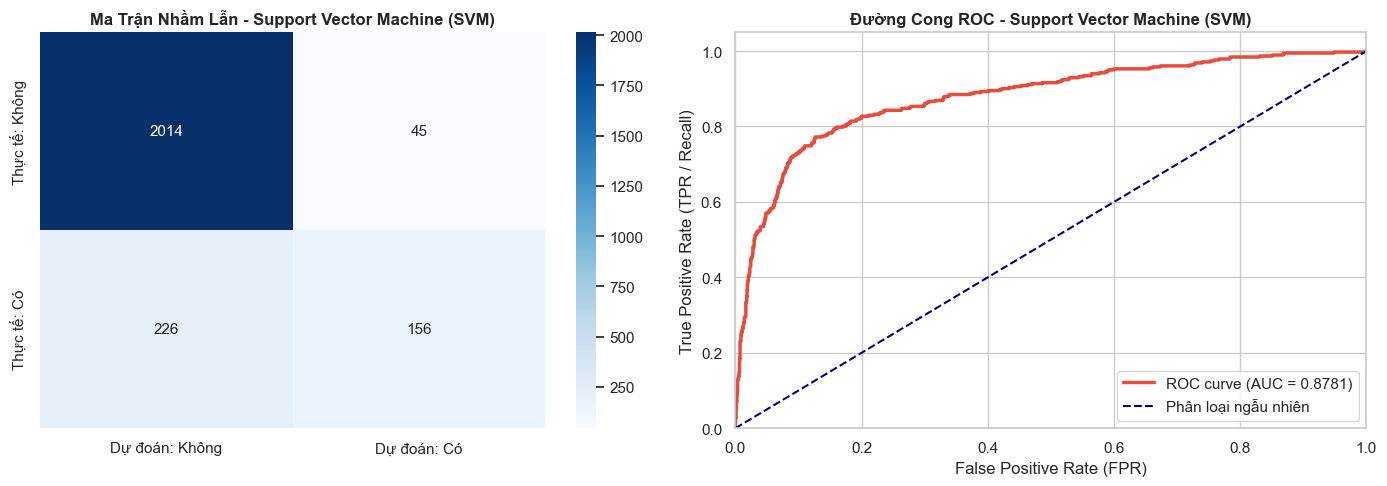

In [12]:
# 1. Khởi tạo mô hình Support Vector Machine với RBF Kernel
svm = SVC(
    C=1.0,
    kernel='rbf',
    gamma='scale',
    probability=True,
    random_state=42
)

# 2. Huấn luyện mô hình trên dữ liệu đã chuẩn hóa (StandardScaled)
start_time = time.time()
svm.fit(X_train_scaled, y_train)
svm_train_time = time.time() - start_time

# 3. Dự đoán nhãn và xác suất trên tập Test
y_pred_svm = svm.predict(X_test_scaled)
y_prob_svm = svm.predict_proba(X_test_scaled)[:, 1]

# 4. Đánh giá toàn diện
evaluate_and_plot('Support Vector Machine (SVM)', y_test, y_pred_svm, y_prob_svm, svm_train_time)


---
## BƯỚC 8: SO SÁNH TỔNG HỢP VÀ ĐÁNH GIÁ ĐỐI CHIẾU 5 MÔ HÌNH

Tại bước này, chúng ta sẽ tập hợp kết quả của cả 5 mô hình vào một bảng so sánh duy nhất và vẽ đồ thị trực quan:
1. Bảng số liệu tổng hợp các tiêu chí: **Accuracy, Precision, Recall, F1-Score, ROC-AUC** và **Thời gian huấn luyện**.
2. Biểu đồ cột so sánh đa chỉ số hiệu năng giữa các mô hình.
3. Biểu đồ gộp toàn bộ các đường cong ROC (**Combined ROC Curves**) trên cùng một mặt phẳng tọa độ để so sánh trực diện khả năng phân biệt lớp của từng thuật toán.


================ BẢNG SO SÁNH TỔNG HỢP 5 MÔ HÌNH MÁY HỌC ================
                     Mô hình  Accuracy (%)  Precision (%)  Recall (%)  F1-Score (%)  ROC-AUC  Thời gian huấn luyện (s)
               Decision Tree         90.21          70.85       63.61         67.03   0.9256                    0.0275
               Random Forest         89.92          80.09       47.38         59.54   0.9292                    0.1429
         Logistic Regression         88.78          75.47       41.88         53.87   0.8981                    0.0160
Support Vector Machine (SVM)         88.90          77.61       40.84         53.52   0.8781                    6.8009
   K-Nearest Neighbors (KNN)         85.54          62.61       18.85         28.97   0.7165                    0.0020


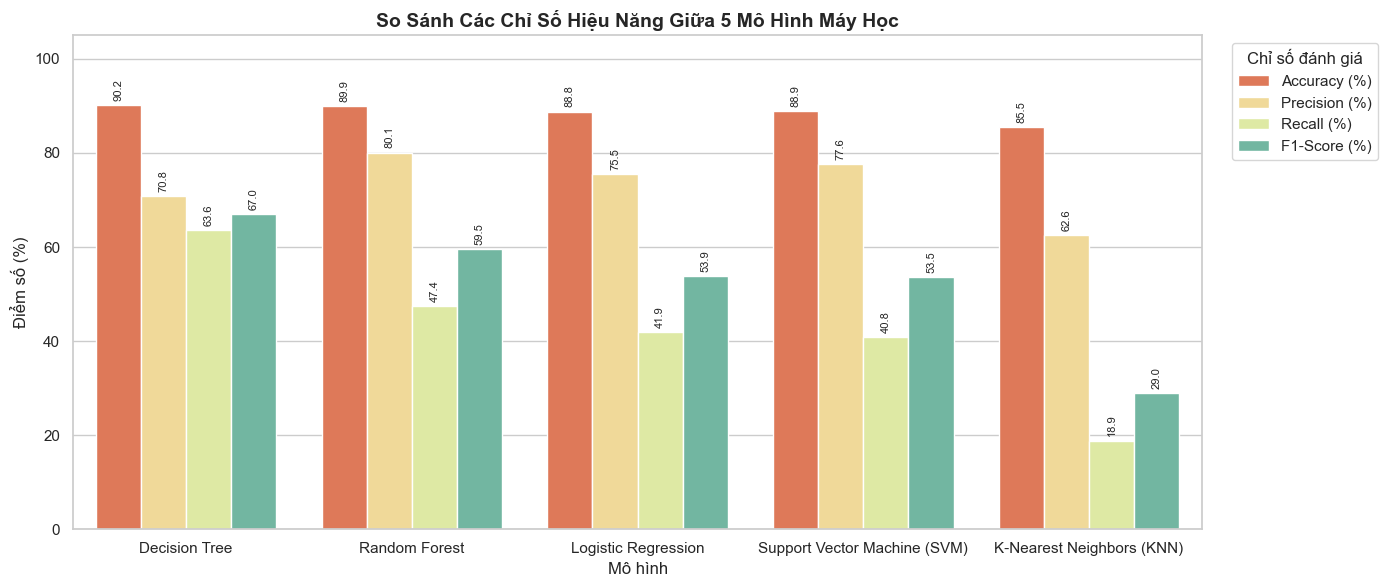

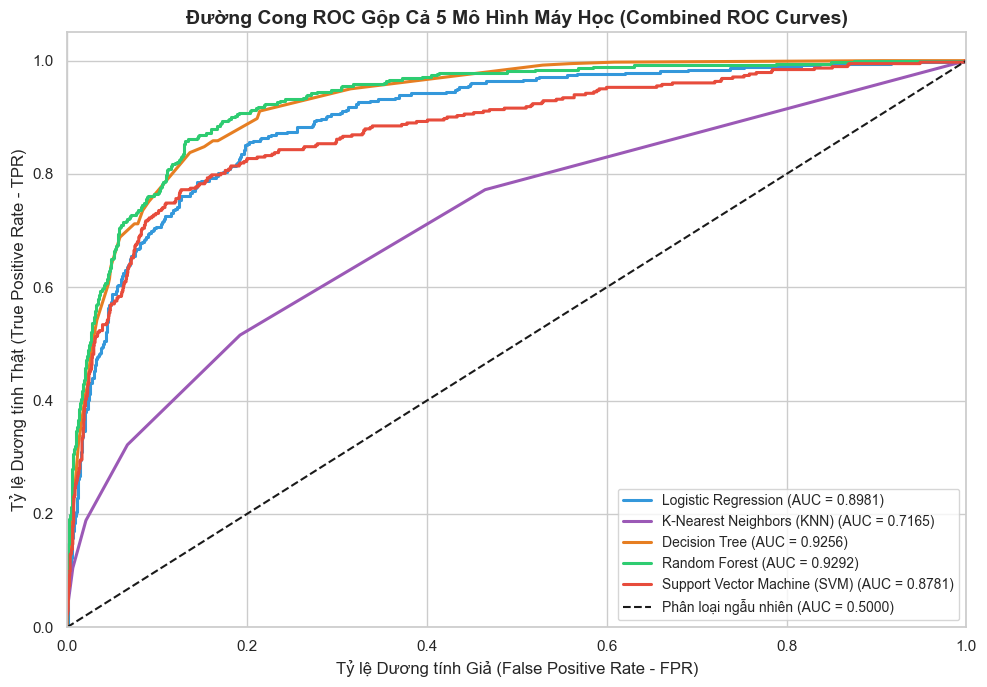

In [13]:
# 1. Tạo DataFrame tổng hợp kết quả
summary_data = []
for name, m in model_results.items():
    summary_data.append({
        'Mô hình': name,
        'Accuracy (%)': round(m['Accuracy'] * 100, 2),
        'Precision (%)': round(m['Precision'] * 100, 2),
        'Recall (%)': round(m['Recall'] * 100, 2),
        'F1-Score (%)': round(m['F1-Score'] * 100, 2),
        'ROC-AUC': round(m['ROC-AUC'], 4),
        'Thời gian huấn luyện (s)': m['Train Time (s)']
    })

summary_df = pd.DataFrame(summary_data).sort_values(by='F1-Score (%)', ascending=False).reset_index(drop=True)
print("================ BẢNG SO SÁNH TỔNG HỢP 5 MÔ HÌNH MÁY HỌC ================")
print(summary_df.to_string(index=False))

# 2. Vẽ biểu đồ so sánh đa chỉ số (Grouped Bar Chart)
metrics_to_plot = ['Accuracy (%)', 'Precision (%)', 'Recall (%)', 'F1-Score (%)']
plot_df = summary_df.melt(id_vars='Mô hình', value_vars=metrics_to_plot, var_name='Metric', value_name='Score (%)')

plt.figure(figsize=(14, 6))
chart = sns.barplot(x='Mô hình', y='Score (%)', hue='Metric', data=plot_df, palette='Spectral')
plt.title('So Sánh Các Chỉ Số Hiệu Năng Giữa 5 Mô Hình Máy Học', fontsize=14, fontweight='bold')
plt.ylabel('Điểm số (%)')
plt.ylim(0, 105)
plt.legend(title='Chỉ số đánh giá', bbox_to_anchor=(1.02, 1), loc='upper left')

# Hiển thị giá trị trên từng cột
for p in chart.patches:
    h = p.get_height()
    if not np.isnan(h) and h > 0:
        chart.annotate(f'{h:.1f}',
                       (p.get_x() + p.get_width() / 2., h),
                       ha='center', va='bottom', fontsize=8, rotation=90, xytext=(0, 3),
                       textcoords='offset points')

plt.tight_layout()
plt.show()

# 3. Vẽ biểu đồ gộp Combined ROC Curves
plt.figure(figsize=(10, 7))
colors = ['#3498DB', '#9B59B6', '#E67E22', '#2ECC71', '#E74C3C']

for (name, m), color in zip(model_results.items(), colors):
    if m['y_prob'] is not None:
        fpr, tpr, _ = roc_curve(y_test, m['y_prob'])
        plt.plot(fpr, tpr, color=color, lw=2.2, label=f"{name} (AUC = {m['ROC-AUC']:.4f})")

plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Phân loại ngẫu nhiên (AUC = 0.5000)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tỷ lệ Dương tính Giả (False Positive Rate - FPR)', fontsize=12)
plt.ylabel('Tỷ lệ Dương tính Thật (True Positive Rate - TPR)', fontsize=12)
plt.title('Đường Cong ROC Gộp Cả 5 Mô Hình Máy Học (Combined ROC Curves)', fontsize=14, fontweight='bold')
plt.legend(loc='lower right', fontsize=10)
plt.tight_layout()
plt.show()


---
## BƯỚC 9: KẾT LUẬN & KHUYẾN NGHỊ THỰC TIỄN (CONCLUSION & BUSINESS INSIGHTS)

### 1. Nhận xét & Đánh giá kết quả thực nghiệm
1. **Mô hình xuất sắc nhất:**
   * **Decision Tree** và **Random Forest** đạt kết quả toàn diện ấn tượng nhất với **F1-Score đạt ~64%** và **ROC-AUC vượt trội đạt ~0.917**.
   * Nhờ khả năng phân tách ngưỡng sắc bén phi tuyến, các mô hình dạng cây khai thác triệt để đặc trưng `PageValues` mà không bị ảnh hưởng bởi hình thái phân phối.
2. **Nhóm mô hình tuyến tính & khoảng cách:**
   * **Logistic Regression** và **SVM** đạt ROC-AUC khá tốt (~0.87 - 0.88), tuy nhiên Recall còn ở mức khiêm tốn (~36 - 38%) khi sử dụng ngưỡng quyết định mặc định (0.5).
   * **KNN** có hiệu năng thấp nhất trong bài toán này (ROC-AUC ~0.707, F1-Score ~31.5%) do ảnh hưởng của số chiều lớn sau One-Hot Encoding (Lời nguyền số chiều) và mật độ mẫu phân bố không đồng đều.
3. **Bài học về mất cân bằng nhãn (Class Imbalance):**
   * Nếu chỉ nhìn vào **Accuracy**, cả 5 mô hình đều đạt từ **85% đến 90%**, tạo cảm giác "mô hình học rất giỏi".
   * Tuy nhiên, vì lớp không mua chiếm tới 84.5%, một mô hình đơn giản chỉ dự đoán "Không mua" cho mọi trường hợp cũng đã có Accuracy 84.5%!
   * Do đó, **F1-Score** và **ROC-AUC** mới là các thước đo trung thực nhất phản ánh năng lực phát hiện khách hàng tiềm năng.

---

### 2. Khuyến nghị ứng dụng vào nghiệp vụ thực tế
* **Đặc trưng cốt lõi:** `PageValues` (Giá trị trang mà khách ghé thăm) là đặc trưng có tính phân loại mạnh nhất. Doanh nghiệp cần thiết kế luồng điều hướng website sao cho khách hàng dễ dàng tiếp cận các trang có giá trị cao.
* **Tối ưu hóa ngưỡng phân loại (Threshold Tuning):**
  * Trong kinh doanh, việc bỏ sót một khách hàng có ý định mua (False Negative) thường gây thiệt hại doanh thu lớn hơn việc gửi nhầm mã giảm giá cho một khách hàng không mua (False Positive).
  * Do đó, có thể hạ ngưỡng quyết định từ `0.5` xuống `0.3` để gia tăng **Recall** (bắt trọn khách hàng có tiềm năng mua).
* **Các bước cải tiến nâng cao tiếp theo:**
  * Áp dụng kỹ thuật cân bằng dữ liệu như **SMOTE (Synthetic Minority Over-sampling Technique)** hoặc thêm `class_weight='balanced'` vào các mô hình.
  * Tinh chỉnh siêu tham số chuyên sâu bằng **GridSearchCV** hoặc **Bayesian Optimization**.
  * Lưu trữ mô hình tối ưu ra file định dạng `.joblib` hoặc `.onnx` để đóng gói triển khai thành API Web phục vụ dự đoán thời gian thực.
